# Street Network Classification — Persistence Diagram Distances

Instead of landscape vectors, we compute **pairwise Wasserstein distances** between H1 persistence diagrams and use the resulting distance matrix as input to a kernel SVM and k-NN classifier.

This avoids the vectorization step entirely and works directly in diagram space.

In [1]:
import numpy as np
import re
from pathlib import Path
from itertools import combinations
from collections import Counter
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

import gudhi
from gudhi.wasserstein import wasserstein_distance

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

## 1. Load persistence diagrams

In [2]:
def find_levelset_root(start=Path.cwd()) -> Path:
    for candidate in [start.resolve(), *start.resolve().parents]:
        if (candidate / "processed_data").exists() and (candidate / "labeled_data").exists():
            return candidate
        nested = candidate / "levelset_urban_ph"
        if (nested / "processed_data").exists() and (nested / "labeled_data").exists():
            return nested
    raise FileNotFoundError(f"Could not find levelset_urban_ph from {start.resolve()}")

LEVELSET_ROOT = find_levelset_root()
NOTEBOOK_DIR = LEVELSET_ROOT / "notebooks_clustering"
DATA_DIR = LEVELSET_ROOT / "processed_data" / "test_us_cities" / "manually_filtered_01"
LABEL_RE   = re.compile(r'(gridiron|cul_de_sac|organico|hibrido)')
CITY_RE    = re.compile(r'^(.+?)_(gridiron|cul_de_sac|organico|hibrido)')

LABEL_RE   = re.compile(r'(gridiron|cul_de_sac)')
CITY_RE    = re.compile(r'^(.+?)_(gridiron|cul_de_sac)')

diagrams, labels, cities, names = [], [], [], []

for folder in sorted(DATA_DIR.iterdir()):
    csv_path = folder / 'h1_pairs.csv'
    if not csv_path.exists():
        continue
    lm = LABEL_RE.search(folder.name)
    cm = CITY_RE.match(folder.name)
    if not lm or not cm:
        continue
    pd = np.loadtxt(csv_path, delimiter=',')
    if pd.ndim == 1:          # single-row edge case
        pd = pd.reshape(1, 2)
    diagrams.append(pd)
    labels.append(lm.group(1))
    cities.append(cm.group(1))
    names.append(folder.name)

y_raw = np.array(labels)
c     = np.array(cities)
le    = LabelEncoder()
y     = le.fit_transform(y_raw)
n     = len(y)

print(f'Diagrams loaded: {n}')
print('Classes:', dict(zip(*np.unique(y_raw, return_counts=True))))
print('Cities:', dict(Counter(cities)))
print(f'Diagram sizes — min: {min(len(d) for d in diagrams)}, '
      f'max: {max(len(d) for d in diagrams)}, '
      f'mean: {np.mean([len(d) for d in diagrams]):.1f}')

Diagrams loaded: 90
Classes: {'cul_de_sac': 39, 'gridiron': 51}
Cities: {'cary_town': 15, 'chandler': 3, 'charleston': 4, 'fort_collins': 8, 'peachtree': 5, 'philadelphia': 38, 'salt_lake': 14, 'santafe': 3}
Diagram sizes — min: 18, max: 279, mean: 74.5


## 2. Compute pairwise Wasserstein distance matrix

Using `gudhi.wasserstein.wasserstein_distance` with order `q=2` (standard W2).  
This is O(n²) — with 150 samples it takes a few minutes.

In [3]:
from tqdm.auto import tqdm

D = np.zeros((n, n))

pairs = [(i, j) for i in range(n) for j in range(i+1, n)]
for i, j in tqdm(pairs, desc='Wasserstein distances'):
    d = wasserstein_distance(diagrams[i], diagrams[j], order=2, enable_autodiff=False)
    D[i, j] = d
    D[j, i] = d

print('Distance matrix shape:', D.shape)
print(f'Min off-diag: {D[D > 0].min():.3f}, Max: {D.max():.3f}, Mean: {D[D > 0].mean():.3f}')

Wasserstein distances: 100%|██████████| 4005/4005 [00:01<00:00, 2951.86it/s]

Distance matrix shape: (90, 90)
Min off-diag: 18.168, Max: 228.908, Mean: 97.255


## 3. Visualize: MDS embedding of the distance matrix

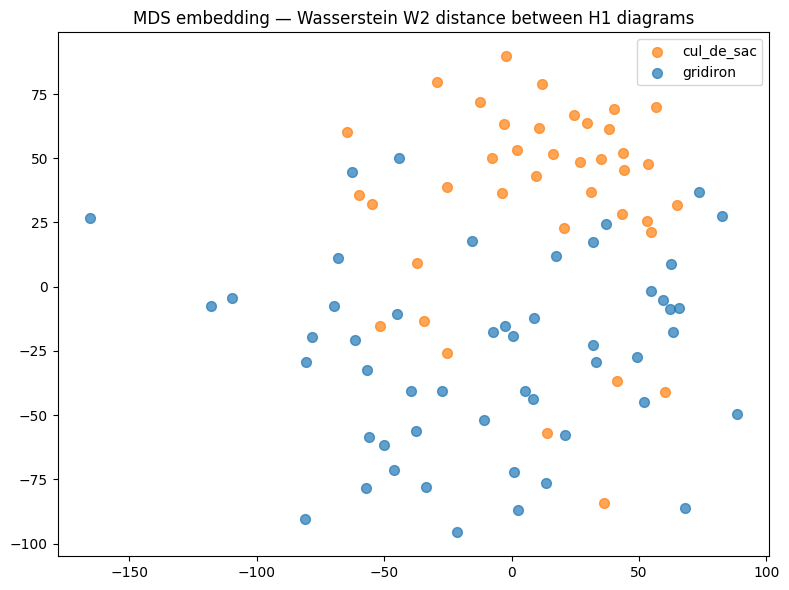

In [4]:
from sklearn.manifold import MDS

mds = MDS(n_components=2, dissimilarity='precomputed', random_state=42, normalized_stress='auto')
Xmds = mds.fit_transform(D)

colors = {'gridiron': 'C0', 'cul_de_sac': 'C1', 'organico': 'C2', 'hibrido': 'C3'}
fig, ax = plt.subplots(figsize=(8, 6))
for cls in np.unique(y_raw):
    mask = y_raw == cls
    ax.scatter(Xmds[mask, 0], Xmds[mask, 1], label=cls, alpha=0.7, s=50, color=colors[cls])
ax.set_title('MDS embedding — Wasserstein W2 distance between H1 diagrams')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Classify using the precomputed distance matrix

- **SVM with precomputed kernel**: convert distance matrix to a Gaussian (RBF) kernel matrix `K = exp(-D² / σ²)`
- **k-NN with precomputed distances**: directly uses D

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- Gaussian kernel from distance matrix ---
sigma = np.median(D[D > 0])          # median heuristic for bandwidth
K = np.exp(-(D ** 2) / (2 * sigma ** 2))
print(f'Kernel bandwidth σ (median heuristic): {sigma:.3f}')

classifiers = {
    'SVM (Gaussian kernel)': SVC(kernel='precomputed', C=10),
    'k-NN (k=5)':            KNeighborsClassifier(n_neighbors=5, metric='precomputed'),
    'k-NN (k=3)':            KNeighborsClassifier(n_neighbors=3, metric='precomputed'),
}

results = {}
for clf_name, clf in classifiers.items():
    X_in = K if 'SVM' in clf_name else D
    scores = cross_val_score(clf, X_in, y, cv=cv, scoring='accuracy')
    results[clf_name] = scores
    print(f'{clf_name:30s} | acc = {scores.mean():.3f} ± {scores.std():.3f}')

Kernel bandwidth σ (median heuristic): 96.247
SVM (Gaussian kernel)          | acc = 0.944 ± 0.035
k-NN (k=5)                     | acc = 0.878 ± 0.082
k-NN (k=3)                     | acc = 0.878 ± 0.082


## 5. Also try: bottleneck distance matrix

In [7]:
D_bn = np.zeros((n, n))
for i, j in tqdm(pairs, desc='Bottleneck distances'):
    d = gudhi.bottleneck_distance(diagrams[i], diagrams[j])
    D_bn[i, j] = d
    D_bn[j, i] = d

sigma_bn = np.median(D_bn[D_bn > 0])
K_bn = np.exp(-(D_bn ** 2) / (2 * sigma_bn ** 2))

for clf_name, clf in [('SVM (Gaussian kernel, bottleneck)', SVC(kernel='precomputed', C=10)),
                       ('k-NN k=5 (bottleneck)',             KNeighborsClassifier(n_neighbors=5, metric='precomputed'))]:
    X_in = K_bn if 'SVM' in clf_name else D_bn
    scores = cross_val_score(clf, X_in, y, cv=cv, scoring='accuracy')
    results[clf_name] = scores
    print(f'{clf_name:40s} | acc = {scores.mean():.3f} ± {scores.std():.3f}')

Bottleneck distances: 100%|██████████| 4005/4005 [00:04<00:00, 985.92it/s] 

SVM (Gaussian kernel, bottleneck)        | acc = 0.511 ± 0.138
k-NN k=5 (bottleneck)                    | acc = 0.800 ± 0.114


## 6. Leave-one-city-out CV — best classifier

In [8]:
from sklearn.metrics import accuracy_score

print('=== Leave-one-city-out (SVM Gaussian kernel, Wasserstein W2) ===')
loco_accs = {}
for city in np.unique(c):
    train, test = c != city, c == city
    K_train = K[np.ix_(train, train)]
    K_test  = K[np.ix_(test,  train)]
    clf = SVC(kernel='precomputed', C=10)
    clf.fit(K_train, y[train])
    acc = accuracy_score(y[test], clf.predict(K_test))
    loco_accs[city] = acc
    print(f'  {city:20s} (n={test.sum():2d}): {acc:.3f}')
print(f'  {"MEAN":20s}: {np.mean(list(loco_accs.values())):.3f}')

=== Leave-one-city-out (SVM Gaussian kernel, Wasserstein W2) ===
  cary_town            (n=15): 1.000
  chandler             (n= 3): 0.667
  charleston           (n= 4): 1.000
  fort_collins         (n= 8): 0.625
  peachtree            (n= 5): 1.000
  philadelphia         (n=38): 0.711
  salt_lake            (n=14): 0.929
  santafe              (n= 3): 1.000
  MEAN                : 0.866


## 7. Confusion matrix — best method (5-fold CV)

## 8. Sample city layouts by predicted class

Best: k-NN (k=5)  acc=0.878
              precision    recall  f1-score   support

  cul_de_sac       0.95      0.92      0.94        39
    gridiron       0.94      0.96      0.95        51

    accuracy                           0.94        90
   macro avg       0.94      0.94      0.94        90
weighted avg       0.94      0.94      0.94        90



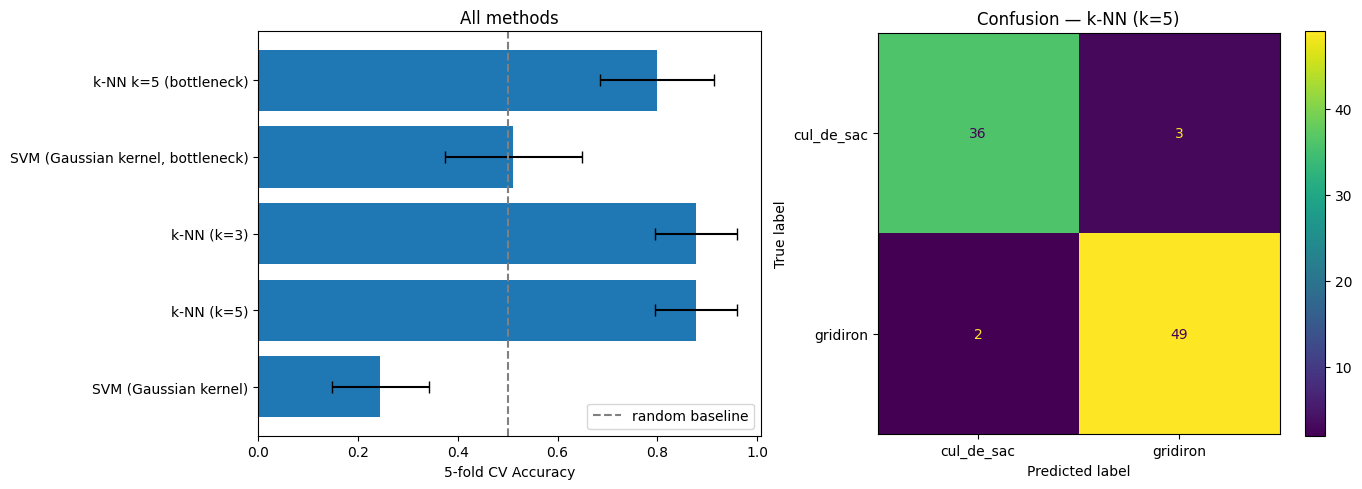

In [9]:
# pick whichever scored highest
best_name = max(results, key=lambda k: results[k].mean())
print(f'Best: {best_name}  acc={results[best_name].mean():.3f}')

best_clf = SVC(kernel='precomputed', C=10)
X_in = K if 'bottleneck' not in best_name else K_bn
y_pred = cross_val_predict(best_clf, X_in, y, cv=cv)

print(classification_report(y, y_pred, target_names=le.classes_))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# bar chart of all methods
ax = axes[0]
names_r = list(results.keys())
means = [results[k].mean() for k in names_r]
stds  = [results[k].std()  for k in names_r]
ax.barh(names_r, means, xerr=stds, capsize=4)
ax.axvline(1/len(le.classes_), color='gray', linestyle='--', label='random baseline')
ax.set_xlabel('5-fold CV Accuracy')
ax.set_title('All methods')
ax.legend()

ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=le.classes_, ax=axes[1])
axes[1].set_title(f'Confusion — {best_name}')

plt.tight_layout()
plt.show()

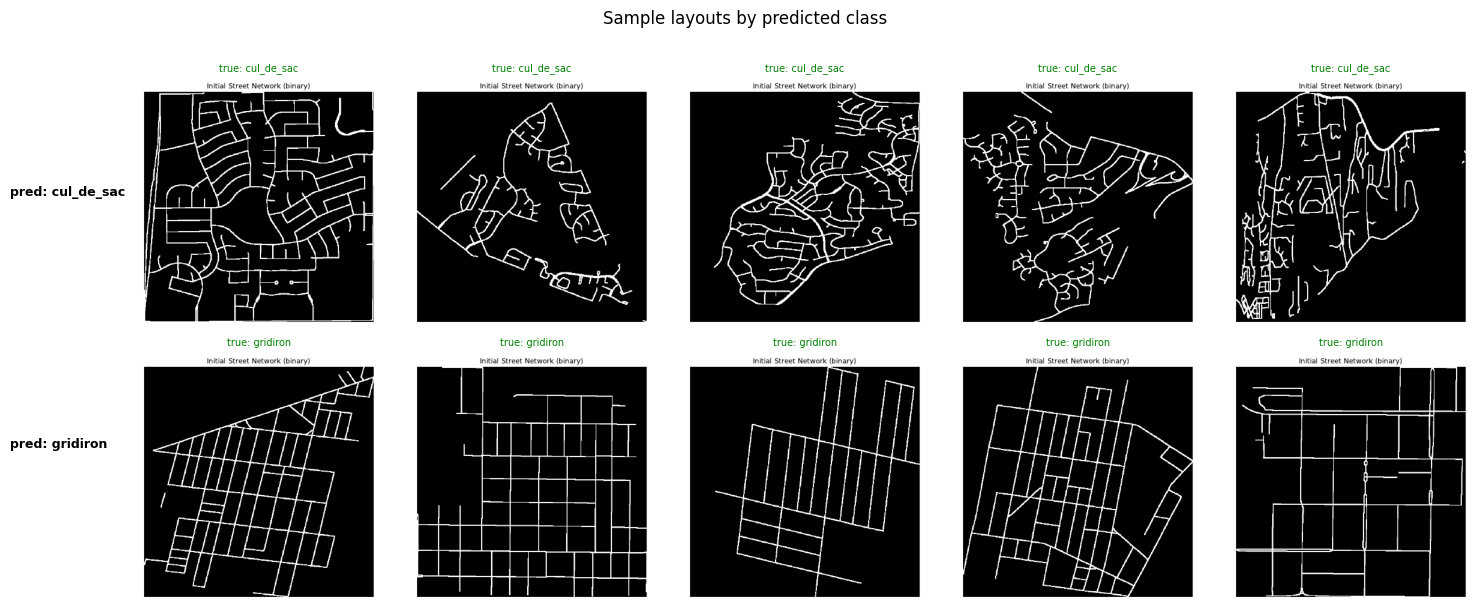

In [13]:
import subprocess, tempfile
from PIL import Image

def pdf_to_img(path):
    with tempfile.TemporaryDirectory() as tmp:
        subprocess.run(["pdftoppm", "-r", "72", "-png", "-singlefile", str(path), f"{tmp}/out"], check=True)
        return np.array(Image.open(f"{tmp}/out.png").copy())

N_SAMPLES = 5
classes = le.classes_
fig, axes = plt.subplots(len(classes), N_SAMPLES, figsize=(N_SAMPLES * 3, len(classes) * 3))

for row, cls in enumerate(classes):
    pool = np.where(y_pred == le.transform([cls])[0])[0]
    cls_idx = np.random.choice(pool, size=min(N_SAMPLES, len(pool)), replace=False)
    for col, idx in enumerate(cls_idx):
        true_cls = y_raw[idx]
        img_path = DATA_DIR / names[idx] / "street_binary.pdf"
        axes[row, col].imshow(pdf_to_img(img_path))
        color = "green" if true_cls == cls else "red"
        axes[row, col].set_title(f"true: {true_cls}", fontsize=7, color=color)
        axes[row, col].axis("off")
    for col in range(len(cls_idx), N_SAMPLES):
        axes[row, col].axis("off")
    fig.text(0.01, axes[row, 0].get_position().y0 + axes[row, 0].get_position().height / 2,
             f"pred: {cls}", va="center", ha="left", fontsize=9, fontweight="bold")

plt.suptitle("Sample layouts by predicted class", y=1.01)
plt.tight_layout(rect=[0.08, 0, 1, 1])
plt.show()
